# Mini Project 14 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_14.py` (bagian wajib) dan `features/mp14_extension_realtime_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 14 — Menyusun dan Menguji Scheduler Streaming Real-Time
Artefak MP13 diubah menjadi **kontrak arsitektur streaming** (DMA double-buffer 10 ms, frame 25 ms,
hop 10 ms, context 96 frame = 975 ms, inference stride 100 ms) yang akan dipindahkan ke perangkat di MP15.
Model, feature schema, dan split **tidak diubah**. Prediksi selama simulasi hanya *sanity check* aliran data.
Status -> `ready_for_mp15`.

Adaptasi terhadap kode buku (tanpa mengubah logika):
* `project_config.json` running project memakai kunci `sample_rate_hz` (buku: `sampling_rate_hz`) -> dibaca dengan fallback.
* ROOT dihitung dari lokasi skrip (folder `Mini Project 14`) agar bisa dijalankan dari mana pun / dari notebook.
* Pemeriksaan status menerima `ready_for_mp14` atau `ready_for_mp15` (rerun idempoten).

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json, time
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import lfilter, lfilter_zi
from scipy.fft import dct
import joblib
import torch
import torch.nn as nn

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
STATUS = ROOT/'project_status.json'
status = json.loads(STATUS.read_text(encoding='utf-8'))
if status.get('status') not in ('ready_for_mp14', 'ready_for_mp15'):
    raise RuntimeError(f"Status harus ready_for_mp14, ditemukan {status.get('status')!r}")
print('Status awal:', status['status'])

Status awal: ready_for_mp14


## 1. Konfigurasi warisan MP1–MP13 dan kontrak timing

In [2]:
project_cfg = json.loads((ROOT/'config/project_config.json').read_text(encoding='utf-8'))
pre_cfg = json.loads((ROOT/'config/preprocessing_config.json').read_text(encoding='utf-8'))
feat_cfg = json.loads((ROOT/'config/feature_config.json').read_text(encoding='utf-8'))
red_cfg = json.loads((ROOT/'config/feature_reduction_config.json').read_text(encoding='utf-8'))
clf_cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
dl_cfg = json.loads((ROOT/'config/deep_learning_config.json').read_text(encoding='utf-8'))
mp13 = json.loads((ROOT/'results/metrics/mp13_final_test_metrics.json').read_text(encoding='utf-8'))

fs = int(project_cfg.get('sampling_rate_hz', project_cfg.get('sample_rate_hz')))
frame_len = int(pre_cfg['frame_length_samples'])
hop_len = int(pre_cfg['hop_length_samples'])
frame_ms = 1000.0 * frame_len / fs
hop_ms = 1000.0 * hop_len / fs
n_mels = int(feat_cfg['mel']['n_mels'])
n_mfcc = int(feat_cfg['mfcc']['n_mfcc'])
context_frames = int(dl_cfg['input_shape_per_sample'][0])
context_ms = frame_ms + (context_frames - 1) * hop_ms
inference_stride_frames = 10   # 100 ms at the running-project hop
inference_stride_ms = inference_stride_frames * hop_ms

dma_block_samples = hop_len
buffer_period_ms = 1000.0 * dma_block_samples / fs
ring_capacity_blocks = 4
print(f'fs={fs} Hz | frame={frame_len} ({frame_ms} ms) | hop={hop_len} ({hop_ms} ms) | '
      f'context={context_frames} frame ({context_ms} ms) | stride={inference_stride_frames} frame ({inference_stride_ms} ms) | '
      f'DMA={dma_block_samples} sampel ({buffer_period_ms} ms)')

fs=16000 Hz | frame=400 (25.0 ms) | hop=160 (10.0 ms) | context=96 frame (975.0 ms) | stride=10 frame (100.0 ms) | DMA=160 sampel (10.0 ms)


## 2. Helper feature per-frame (streaming) + agregasi 39-D

In [3]:
def hz_to_mel(f):
    return 2595.0 * np.log10(1.0 + np.asarray(f) / 700.0)


def mel_to_hz(m):
    return 700.0 * (10.0**(np.asarray(m) / 2595.0) - 1.0)


def make_mel_filterbank(n_fft, fs, n_mels=26, fmin=80.0, fmax=7600.0):
    n_bins = n_fft // 2 + 1
    mel_pts = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    hz_pts = mel_to_hz(mel_pts)
    bins = np.floor((n_fft + 1) * hz_pts / fs).astype(int)
    bins = np.clip(bins, 0, n_bins - 1)
    fb = np.zeros((n_mels, n_bins), dtype=np.float64)
    for m in range(1, n_mels + 1):
        left, center, right = bins[m-1], bins[m], bins[m+1]
        center = max(center, left + 1)
        right = max(right, center + 1)
        right = min(right, n_bins - 1)
        for k in range(left, min(center, n_bins)):
            fb[m-1, k] = (k - left) / max(1, center - left)
        for k in range(center, min(right + 1, n_bins)):
            fb[m-1, k] = (right - k) / max(1, right - center)
    return fb


freq = np.fft.rfftfreq(frame_len, d=1.0/fs)
fb = make_mel_filterbank(frame_len, fs, n_mels, float(feat_cfg['mel']['fmin_hz']), min(float(feat_cfg['mel']['fmax_hz']), 0.95*fs/2))
window = np.hamming(frame_len)
lag_min = max(1, int(fs / float(feat_cfg['pitch']['max_hz'])))
lag_max = min(frame_len - 2, int(fs / float(feat_cfg['pitch']['min_hz'])))


def frame_features(frame):
    x = np.asarray(frame, dtype=np.float64)
    x = x - np.mean(x)
    peak = np.max(np.abs(x)) + 1e-12
    x = x * min(1.0, 0.95 / peak)
    alpha = float(pre_cfg['pre_emphasis_alpha'])
    x = np.r_[x[0], x[1:] - alpha*x[:-1]]
    xw = x * window
    rms = float(np.sqrt(np.mean(xw*xw) + 1e-12))
    zcr = float(np.mean(np.abs(np.diff(np.signbit(xw)))))
    X = np.fft.rfft(xw)
    power = np.abs(X)**2 + 1e-15
    psum = np.sum(power) + 1e-15
    centroid = float(np.sum(power * freq) / psum)
    bandwidth = float(np.sqrt(np.sum(power * (freq-centroid)**2) / psum))
    cum = np.cumsum(power)
    idx = int(np.searchsorted(cum, 0.85*cum[-1]))
    rolloff = float(freq[min(idx, len(freq)-1)])
    mel = np.maximum(power @ fb.T, 1e-12)
    logmel = np.log(mel).astype(np.float32)
    mfcc = dct(logmel, type=2, norm='ortho')[:n_mfcc].astype(np.float32)
    f0 = 0.0; conf = 0.0
    ac = np.correlate(xw, xw, mode='full')[frame_len-1:]
    if ac[0] > 1e-12:
        ac = ac/ac[0]
        search = ac[lag_min:lag_max+1]
        if len(search):
            lag = int(np.argmax(search)) + lag_min
            conf = float(ac[lag])
            if conf >= float(feat_cfg['pitch']['confidence_threshold']):
                f0 = float(fs/lag)
    return {'logmel': logmel, 'mfcc': mfcc, 'rms': rms, 'zcr': zcr, 'centroid': centroid,
            'bandwidth': bandwidth, 'rolloff': rolloff, 'f0': f0, 'voiced': f0 > 0}


def aggregate_39(hist):
    vals = []
    mfcc = np.stack([h['mfcc'] for h in hist])

    def ms(a, mask=None):
        a = np.asarray(a, dtype=np.float64)
        if mask is not None: a = a[np.asarray(mask, dtype=bool)]
        return (0.0, 0.0) if a.size == 0 else (float(a.mean()), float(a.std()))
    for j in range(n_mfcc): vals.extend(ms(mfcc[:, j]))
    for key in ['rms', 'zcr', 'centroid', 'bandwidth', 'rolloff']:
        vals.extend(ms([h[key] for h in hist]))
    voiced = np.array([h['voiced'] for h in hist], dtype=bool)
    vals.extend(ms([h['f0'] for h in hist], voiced))
    vals.append(float(voiced.mean()))
    return np.asarray(vals, dtype=np.float32)

## 3. Muat kedua model kandidat (beku) + warm-up

In [4]:
class TinyKWSNet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(), nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Linear(16, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


classic_model = joblib.load(ROOT/clf_cfg['model_file'])
ckpt = torch.load(ROOT/dl_cfg['model_file'], map_location='cpu', weights_only=False)
dl_classes = list(ckpt['classes']); mu = float(ckpt['normalization']['mean']); sigma = float(ckpt['normalization']['std'])
tiny = TinyKWSNet(len(dl_classes)); tiny.load_state_dict(ckpt['state_dict']); tiny.eval()
selected = np.asarray(red_cfg['selected_indices'], dtype=int)
scaler_mean = np.asarray(red_cfg['scaler_mean'], dtype=np.float32)
scaler_scale = np.asarray(red_cfg['scaler_scale'], dtype=np.float32)

# Warm-up inference runtimes.
with torch.no_grad():
    dummy = torch.zeros((1, 1, context_frames, n_mels), dtype=torch.float32)
    for _ in range(5): tiny(dummy)
for _ in range(5): classic_model.predict(np.zeros((1, len(selected)), dtype=np.float32))
print('Classical family:', clf_cfg['chosen_family'], '| CNN classes:', dl_classes, '| selected idx:', selected.tolist())

Classical family: tree | CNN classes: ['mati', 'naik', 'nyala', 'turun'] | selected idx: [2, 3, 7, 8, 28, 29, 30, 31]


## 4. Simulasi streaming DMA block-by-block (virtual CPU + ring buffer 4 blok)
Input: blok training `nyala_b01.wav` (tidak memakai test untuk desain arsitektur), diulang 4x.

In [5]:
source = ROOT/'data/raw/mp09_dataset/nyala_b01.wav'  # training block; no reuse of test for architecture design
sr, audio = wavfile.read(source)
if sr != fs: raise RuntimeError(f'sampling rate {sr} != {fs}')
if audio.ndim > 1: audio = audio[:, 0]
if np.issubdtype(audio.dtype, np.integer):
    audio = audio.astype(np.float64)/max(abs(np.iinfo(audio.dtype).min), np.iinfo(audio.dtype).max)
else: audio = audio.astype(np.float64)
# Repeat to obtain several inference opportunities without collecting new data.
audio = np.tile(audio, 4)

# Final filter from MP6 as a stateful streaming filter.
filt = np.load(ROOT/status['filter_final_coefficients'], allow_pickle=True)
b = np.asarray(filt['b'], dtype=np.float64); a = np.asarray(filt['a'], dtype=np.float64)
zi = lfilter_zi(b, a)*0.0

pcm = []; feature_hist = []
trace = []; classic_ms = []; cnn_ms = []; labels_trace = []
virtual_cpu_ready = 0.0
frame_counter = 0
n_infer = 0

for bi, start in enumerate(range(0, len(audio), dma_block_samples)):
    block = audio[start:start+dma_block_samples]
    if len(block) < dma_block_samples: break
    arrival_ms = bi*buffer_period_ms
    t0 = time.perf_counter()
    y, zi = lfilter(b, a, block, zi=zi)
    pcm.extend(y.tolist())
    if len(pcm) > frame_len: pcm = pcm[-frame_len:]
    did_infer = False; pred_c = ''; pred_d = ''
    if len(pcm) == frame_len:
        ff = frame_features(np.asarray(pcm))
        feature_hist.append(ff)
        if len(feature_hist) > context_frames: feature_hist = feature_hist[-context_frames:]
        frame_counter += 1
        if len(feature_hist) == context_frames and (frame_counter-context_frames) % inference_stride_frames == 0:
            did_infer = True; n_infer += 1
            full = aggregate_39(feature_hist)
            x8 = ((full-scaler_mean)/scaler_scale)[selected][None, :]
            tc = time.perf_counter(); pred_c = str(classic_model.predict(x8)[0]); classic_ms.append((time.perf_counter()-tc)*1000)
            lm = np.stack([h['logmel'] for h in feature_hist]).astype(np.float32)
            x = torch.from_numpy(((lm-mu)/sigma)[None, None, ...]).float()
            td = time.perf_counter()
            with torch.no_grad(): pred_d = dl_classes[int(tiny(x).argmax(1).item())]
            cnn_ms.append((time.perf_counter()-td)*1000)
            labels_trace.append((bi, pred_c, pred_d))
    compute_ms = (time.perf_counter()-t0)*1000
    start_ms = max(arrival_ms, virtual_cpu_ready)
    finish_ms = start_ms+compute_ms
    waiting_ms = start_ms-arrival_ms
    queue_blocks = int(np.floor(waiting_ms/buffer_period_ms+1e-12))
    overflow = queue_blocks >= ring_capacity_blocks
    virtual_cpu_ready = finish_ms
    trace.append([bi, arrival_ms, compute_ms, waiting_ms, queue_blocks, int(did_infer), int(overflow)])

trace = np.asarray(trace, dtype=np.float64)
print('Sanity-check label (block, classical, cnn):', labels_trace)

Sanity-check label (block, classical, cnn): [(97, 'turun', 'mati'), (107, 'turun', 'mati'), (117, 'turun', 'turun'), (127, 'turun', 'turun'), (137, 'turun', 'turun'), (147, 'turun', 'turun'), (157, 'turun', 'turun'), (167, 'turun', 'turun'), (177, 'turun', 'turun'), (187, 'turun', 'turun'), (197, 'turun', 'mati'), (207, 'turun', 'mati'), (217, 'turun', 'mati'), (227, 'turun', 'mati'), (237, 'turun', 'turun'), (247, 'turun', 'turun'), (257, 'turun', 'turun'), (267, 'turun', 'turun'), (277, 'turun', 'turun'), (287, 'turun', 'turun'), (297, 'turun', 'turun'), (307, 'turun', 'turun'), (317, 'turun', 'mati'), (327, 'turun', 'mati'), (337, 'turun', 'mati'), (347, 'turun', 'mati'), (357, 'turun', 'turun'), (367, 'turun', 'turun'), (377, 'turun', 'turun'), (387, 'turun', 'turun'), (397, 'turun', 'turun'), (407, 'turun', 'turun'), (417, 'turun', 'turun'), (427, 'turun', 'turun'), (437, 'turun', 'mati'), (447, 'turun', 'mati'), (457, 'turun', 'mati'), (467, 'turun', 'mati'), (477, 'turun', 'turu

## 5. Memory budget proxy, metrik, konfigurasi arsitektur, header C

In [6]:
# Memory proxy. MP15 will measure real target memory.
dma_bytes = 2*dma_block_samples*2
pcm_ring_bytes = frame_len*2
logmel_ring_bytes = context_frames*n_mels*4
classical_frame_state_bytes = context_frames*(13+7)*4
# Float32 activation upper bound: first conv output 8*T*F before pooling.
activation_proxy_bytes = 8*context_frames*n_mels*4
cnn_weight_bytes = int(mp13['resource_proxy']['tiny_cnn']['float32_parameter_bytes'])
classical_serialized = int(mp13['resource_proxy']['classical']['serialized_bytes'])

metrics = {
    'source_audio': str(source.relative_to(ROOT).as_posix()),
    'stream_duration_s': float(len(audio)/fs),
    'sample_rate_hz': fs,
    'dma_block_samples': dma_block_samples,
    'dma_block_ms': buffer_period_ms,
    'double_buffer': True,
    'ring_capacity_blocks': ring_capacity_blocks,
    'frame_samples': frame_len,
    'frame_ms': frame_ms,
    'hop_samples': hop_len,
    'hop_ms': hop_ms,
    'context_frames': context_frames,
    'context_ms': context_ms,
    'inference_stride_frames': inference_stride_frames,
    'inference_stride_ms': inference_stride_ms,
    'n_blocks': int(len(trace)),
    'n_inferences': int(n_infer),
    'mean_block_compute_ms': float(trace[:, 2].mean()),
    'p95_block_compute_ms': float(np.percentile(trace[:, 2], 95)),
    'max_block_compute_ms': float(trace[:, 2].max()),
    'max_waiting_ms': float(trace[:, 3].max()),
    'max_queue_blocks': int(trace[:, 4].max()),
    'overflow_count': int(trace[:, 6].sum()),
    'realtime_condition_pass': bool(trace[:, 6].sum() == 0 and np.percentile(trace[:, 2], 95) < buffer_period_ms),
    'classical_inference_ms_mean': float(np.mean(classic_ms) if classic_ms else 0),
    'classical_inference_ms_p95': float(np.percentile(classic_ms, 95) if classic_ms else 0),
    'tiny_cnn_inference_ms_mean': float(np.mean(cnn_ms) if cnn_ms else 0),
    'tiny_cnn_inference_ms_p95': float(np.percentile(cnn_ms, 95) if cnn_ms else 0),
    'memory_proxy_bytes': {
        'dma_double_buffer_int16': dma_bytes,
        'pcm_frame_ring_int16': pcm_ring_bytes,
        'logmel_context_float32': logmel_ring_bytes,
        'classical_frame_state_float32': classical_frame_state_bytes,
        'tiny_cnn_activation_float32_upper_proxy': activation_proxy_bytes,
        'tiny_cnn_weights_float32': cnn_weight_bytes,
        'classical_serialized_model': classical_serialized,
    },
    'sanity_labels': [list(map(str, t)) for t in labels_trace],
    'interpretation': 'Host-side scheduling and memory proxy only. Target-device latency, peak RAM, flash, and power must be measured in MP15.',
    'deployment_model_selected': False,
    'deployment_selection_deferred_to': 'MP15'
}

config = {
    'sample_rate_hz': fs,
    'input_interface': 'I2S_or_ADC_to_DMA',
    'dma_block_samples': dma_block_samples,
    'dma_buffer_count': 2,
    'dma_block_ms': buffer_period_ms,
    'pcm_ring_samples': frame_len,
    'feature_hop_samples': hop_len,
    'feature_frame_samples': frame_len,
    'feature_context_frames': context_frames,
    'feature_context_ms': context_ms,
    'inference_stride_frames': inference_stride_frames,
    'inference_stride_ms': inference_stride_ms,
    'ring_capacity_blocks': ring_capacity_blocks,
    'scheduler': 'DMA ISR only signals buffer-ready; DSP/feature/inference run outside ISR',
    'candidate_models': ['mp11_classical_baseline', 'mp12_tiny_cnn'],
    'final_model_selection': 'DEFERRED_TO_MP15',
    'overflow_policy': 'increment_counter_and_drop_oldest_unprocessed_block',
    'instrumentation': ['frame_counter', 'overflow_counter', 'timestamp_us', 'stage_latency_us']
}

(ROOT/'config').mkdir(exist_ok=True)
(ROOT/'results/metrics').mkdir(parents=True, exist_ok=True)
(ROOT/'results/figures').mkdir(parents=True, exist_ok=True)
(ROOT/'features/intermediate').mkdir(parents=True, exist_ok=True)
(ROOT/'firmware').mkdir(parents=True, exist_ok=True)
(ROOT/'config/realtime_architecture_config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
(ROOT/'results/metrics/mp14_realtime_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
np.savez_compressed(ROOT/'features/intermediate/mp14_stream_trace.npz', trace=trace,
                    columns=np.array(['block', 'arrival_ms', 'compute_ms', 'waiting_ms', 'queue_blocks', 'did_infer', 'overflow'], dtype=object))

# Header constants for MP15 firmware integration.
header = (f'#pragma once\n// Auto-generated by Mini Project 14\n#define AUDIO_FS_HZ {fs}\n#define DMA_BLOCK_SAMPLES {dma_block_samples}\n'
          f'#define DMA_BUFFER_COUNT 2\n#define AUDIO_FRAME_SAMPLES {frame_len}\n#define FEATURE_HOP_SAMPLES {hop_len}\n'
          f'#define FEATURE_CONTEXT_FRAMES {context_frames}\n#define INFERENCE_STRIDE_FRAMES {inference_stride_frames}\n'
          f'#define AUDIO_RING_CAPACITY_BLOCKS {ring_capacity_blocks}\n')
(ROOT/'firmware/mp14_realtime_constants.h').write_text(header, encoding='utf-8')
print(header)

#pragma once
// Auto-generated by Mini Project 14
#define AUDIO_FS_HZ 16000
#define DMA_BLOCK_SAMPLES 160
#define DMA_BUFFER_COUNT 2
#define AUDIO_FRAME_SAMPLES 400
#define FEATURE_HOP_SAMPLES 160
#define FEATURE_CONTEXT_FRAMES 96
#define INFERENCE_STRIDE_FRAMES 10
#define AUDIO_RING_CAPACITY_BLOCKS 4



## 6. Visualisasi: timing trace & memory budget

In [7]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.plot(trace[:, 1], trace[:, 2], lw=1, label='compute per DMA block')
ax.axhline(buffer_period_ms, ls='--', lw=1, label='DMA block period')
ax.set_xlabel('Stream time (ms)'); ax.set_ylabel('Host compute time (ms)'); ax.grid(alpha=.2); ax.legend()
ax.set_title('MP14 host-side real-time scheduling trace'); fig.tight_layout(); fig.savefig(ROOT/'results/figures/mp14_timing_trace.png', dpi=170); plt.close(fig)

mem = metrics['memory_proxy_bytes']; names = list(mem.keys()); vals = np.array(list(mem.values()), dtype=float)/1024.0
fig, ax = plt.subplots(figsize=(8.0, 4.4)); ax.barh(np.arange(len(names)), vals); ax.set_yticks(np.arange(len(names)))
ax.set_yticklabels([n.replace('_', ' ') for n in names], fontsize=8); ax.set_xlabel('KiB'); ax.set_title('MP14 memory budget proxy')
ax.grid(axis='x', alpha=.2); fig.tight_layout()
fig.savefig(ROOT/'results/figures/mp14_memory_budget.png', dpi=170); plt.close(fig)

## 7. Update project status + tabel validasi

In [8]:
status['status'] = 'ready_for_mp15'; status['last_completed_mini_project'] = 14
done = set(status.get('completed_mini_projects', [])); done.add(14); status['completed_mini_projects'] = sorted(done)
status['mp14'] = {
    'realtime_config': 'config/realtime_architecture_config.json',
    'stream_trace': 'features/intermediate/mp14_stream_trace.npz',
    'metrics': 'results/metrics/mp14_realtime_metrics.json',
    'firmware_constants': 'firmware/mp14_realtime_constants.h',
    'timing_figure': 'results/figures/mp14_timing_trace.png',
    'memory_figure': 'results/figures/mp14_memory_budget.png',
    'deployment_candidates': ['models/mp11_classical_baseline.joblib', 'models/mp12_tiny_cnn_state.pt'],
    'deployment_selection_deferred_to': 'MP15'
}
STATUS.write_text(json.dumps(status, indent=2), encoding='utf-8')

print('MP14 selesai')
print('blocks:', len(trace), 'inferences:', n_infer)
print('p95 block compute ms:', round(metrics['p95_block_compute_ms'], 4), 'period ms:', buffer_period_ms)
print('max queue blocks:', metrics['max_queue_blocks'], 'overflow:', metrics['overflow_count'])
print('classical infer mean ms:', round(metrics['classical_inference_ms_mean'], 4))
print('tiny cnn infer mean ms:', round(metrics['tiny_cnn_inference_ms_mean'], 4))
biggest = max(mem, key=mem.get)
print('komponen RAM proxy terbesar:', biggest, f'({mem[biggest]/1024:.2f} KiB)')
checks = [('Status awal', 'ready_for_mp14', 'ready_for_mp14 (diverifikasi di sel 1)'),
          ('DMA period', '10 ms', f'{buffer_period_ms} ms'),
          ('Context', '96 frame / 975 ms', f'{context_frames} frame / {context_ms} ms'),
          ('Inference stride', '100 ms', f'{inference_stride_ms} ms'),
          ('Overflow count', '0', str(metrics['overflow_count'])),
          ('Realtime condition', 'True', str(metrics['realtime_condition_pass'])),
          ('Model selection', 'False / deferred', f"{metrics['deployment_model_selected']} / {metrics['deployment_selection_deferred_to']}"),
          ('Header C', 'tersedia', str((ROOT/'firmware/mp14_realtime_constants.h').exists())),
          ('Status akhir', 'ready_for_mp15', status['status'])]
print(f"\n{'Pemeriksaan':20s} | {'Kriteria lulus':20s} | Hasil")
for c in checks: print(f'{c[0]:20s} | {c[1]:20s} | {c[2]}')
assert metrics['overflow_count'] == 0 and metrics['realtime_condition_pass']
print('status:', status['status'])

MP14 selesai
blocks: 480 inferences: 39
p95 block compute ms: 1.3125 period ms: 10.0
max queue blocks: 0 overflow: 0
classical infer mean ms: 0.1158
tiny cnn infer mean ms: 0.2921
komponen RAM proxy terbesar: tiny_cnn_activation_float32_upper_proxy (78.00 KiB)

Pemeriksaan          | Kriteria lulus       | Hasil
Status awal          | ready_for_mp14       | ready_for_mp14 (diverifikasi di sel 1)
DMA period           | 10 ms                | 10.0 ms
Context              | 96 frame / 975 ms    | 96 frame / 975.0 ms
Inference stride     | 100 ms               | 100.0 ms
Overflow count       | 0                    | 0
Realtime condition   | True                 | True
Model selection      | False / deferred     | False / MP15
Header C             | tersedia             | True
Status akhir         | ready_for_mp15       | ready_for_mp15
status: ready_for_mp15


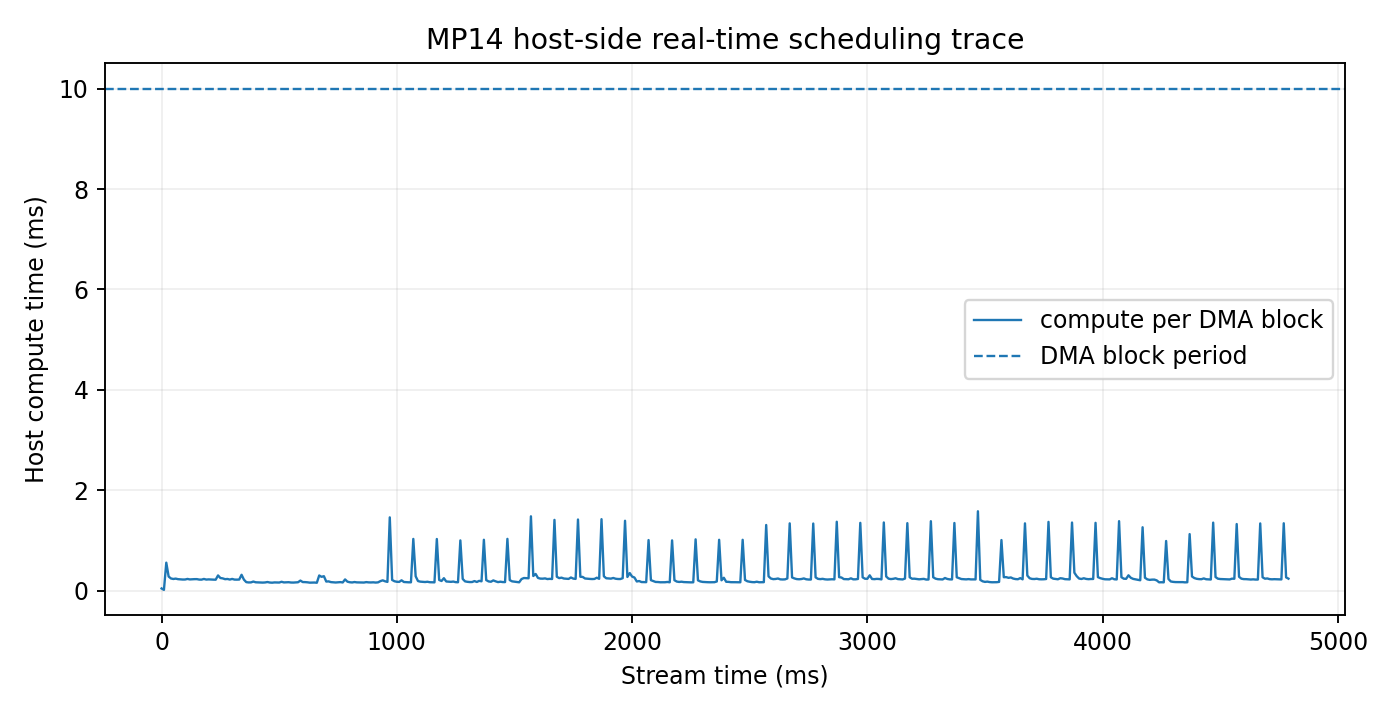

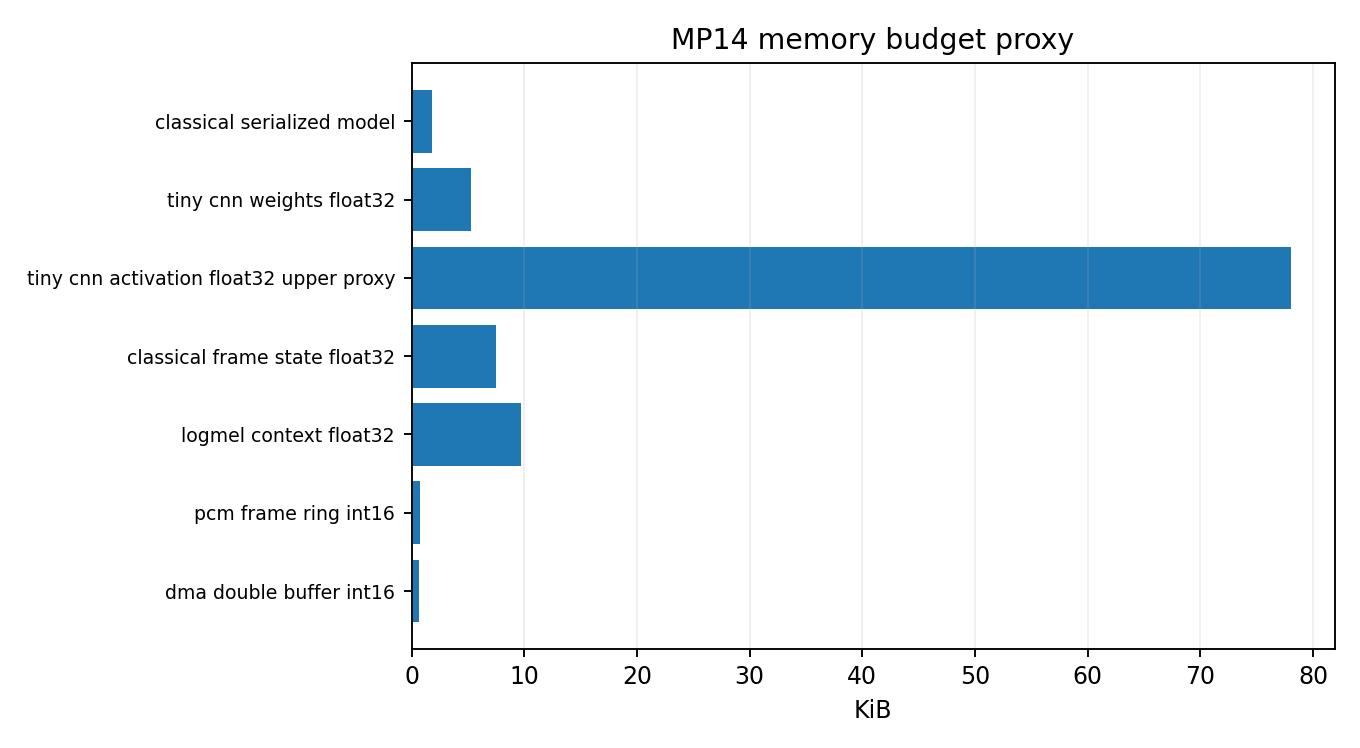

In [9]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp14_timing_trace.png', 'mp14_memory_budget.png']:
        display(Image(filename=str(ROOT/'results/figures'/p), width=720))

---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp14_extension_realtime_analysis.py`

## FITUR TAMBAHAN MP14 — Stress Test Scheduler, Proyeksi MCU, Streaming KWS Kontinu & Ring Buffer C
Modul mandiri setelah `mini_project_14.py`. Kontrak timing MP14 **tidak diubah**; model tidak dilatih ulang.
Semua audio yang dipakai adalah blok **train+validation** (test tidak dipakai untuk desain arsitektur).

1. **Profil per-stage** (filter, feature/frame, classical, CNN) di host + **proyeksi ke MCU** (ESP32-S3 240 MHz)
   berbasis hitungan MAC (asumsi dinyatakan eksplisit).
2. **CPU-load stress sweep**: compute diperlambat 1x–256x → kapan ring buffer 4 blok overflow? utilisasi, latensi p99, jitter.
3. **Inference-stride sweep** 50–500 ms: beban CPU vs latensi deteksi terburuk.
4. **Streaming KWS kontinu**: 20 ucapan train+val disambung dengan jeda derau; jendela 975 ms tiap 100 ms memakai
   front-end beku (`kws_frontend.py`) + model klasik; dibandingkan *raw* vs *energy gate* (duty-cycling) vs
   *gate + posterior smoothing + debounce/refractory* (materi Bab 14: deteksi event pada stream).
5. **Ring buffer C** (drop-oldest, kapasitas 4, critical-section macro) dikompilasi `gcc` & diuji terhadap model Python.
6. **Gantt chart** ISR / DSP / feature / inferensi pada 300 ms stream.

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [10]:
from pathlib import Path
import json, sys, time, shutil, subprocess
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib

ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT/'features'))
from kws_frontend import KWSFrontend  # noqa: E402

status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp15',), 'Jalankan mini_project_14.py terlebih dahulu'
rt = json.loads((ROOT/'config/realtime_architecture_config.json').read_text(encoding='utf-8'))
m14 = json.loads((ROOT/'results/metrics/mp14_realtime_metrics.json').read_text(encoding='utf-8'))
red = json.loads((ROOT/'config/feature_reduction_config.json').read_text(encoding='utf-8'))
clf_cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
mp13 = json.loads((ROOT/'results/metrics/mp13_final_test_metrics.json').read_text(encoding='utf-8'))
split = json.loads((ROOT/'splits/mp09_split.json').read_text(encoding='utf-8'))
OUT_MET, OUT_FIG = ROOT/'results/metrics', ROOT/'results/figures'
fs = rt['sample_rate_hz']; BLK = rt['dma_block_samples']; PERIOD = rt['dma_block_ms']
CTX = rt['feature_context_frames']; STRIDE = rt['inference_stride_frames']; CAP = rt['ring_capacity_blocks']
fe = KWSFrontend(ROOT)
clf = joblib.load(ROOT/clf_cfg['model_file'])
SEL = np.asarray(red['selected_indices'], int); MU = np.asarray(red['scaler_mean']); SC = np.asarray(red['scaler_scale'])
rng = np.random.default_rng(2026)

# Fungsi streaming per-frame milik skrip utama (sel 1–2) dimuat ulang agar profil stage identik dengan MP14
src = (ROOT/'mini_project_14.py').read_text(encoding='utf-8')
ns = {'__name__': 'mp14_main_helpers', '__file__': str(ROOT/'mini_project_14.py')}
exec(src[:src.index('# ## 3. Muat kedua model')], ns)

Status awal: ready_for_mp15
fs=16000 Hz | frame=400 (25.0 ms) | hop=160 (10.0 ms) | context=96 frame (975.0 ms) | stride=10 frame (100.0 ms) | DMA=160 sampel (10.0 ms)


### 1. Profil per-stage di host + proyeksi MCU

In [11]:
import torch
from scipy.signal import lfilter
ck = torch.load(ROOT/'models/mp12_tiny_cnn_state.pt', map_location='cpu', weights_only=False)
exec(src[src.index('class TinyKWSNet'):src.index('classic_model = joblib.load')], ns)
cnn = ns['TinyKWSNet'](len(ck['classes'])); cnn.load_state_dict(ck['state_dict']); cnn.eval()
blk = rng.normal(scale=.05, size=BLK); frm = rng.normal(scale=.05, size=rt['feature_frame_samples'])
b, a = fe.b, fe.a


def bench(fn, n=300):
    for _ in range(10): fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter()-t0)*1e3)
    return float(np.median(t)), float(np.percentile(t, 99))


hist = [ns['frame_features'](frm) for _ in range(CTX)]
x8 = np.zeros((1, len(SEL)))
lm = torch.zeros((1, 1, CTX, 26))
stage_host = {
    'iir_filter_per_block': bench(lambda: lfilter(b, a, blk)),
    'frame_features_full_per_hop': bench(lambda: ns['frame_features'](frm), 200),
    'aggregate39_per_inference': bench(lambda: ns['aggregate_39'](hist), 100),
    'classical_predict_per_inference': bench(lambda: clf.predict(x8)),
    'tiny_cnn_per_inference': bench(lambda: cnn(lm), 100),
}
print('Host median / p99 (ms):', {k: tuple(round(x, 4) for x in v) for k, v in stage_host.items()})

# Proyeksi MCU (asumsi eksplisit) — ESP32-S3 @240 MHz, FPU single-precision, ~4 siklus/MAC efektif (load+MAC+loop overhead)
MCU = {'name': 'ESP32-S3 (Xtensa LX7) @240MHz', 'f_hz': 240e6, 'cycles_per_mac_float': 4.0, 'cycles_per_mac_int8': 1.0}
fe_cost = json.loads((ROOT/'results/metrics/mp10_extension_selection_metrics.json').read_text(encoding='utf-8'))['front_end_cost']
mac = {
    'iir_filter_per_block': BLK*(len(b)+len(a)-1),
    'frame_features_full_per_hop': fe_cost['mac_per_frame_full39'],
    'frame_features_selected_per_hop': fe_cost['mac_per_frame_selected'],
    'classical_tree_per_inference': mp13['resource_proxy']['classical']['estimated_ops_per_sample'] + 2*len(SEL),
    'tiny_cnn_per_inference': mp13['resource_proxy']['tiny_cnn']['estimated_macs_per_inference'],
}
mcu_ms = {k: 1e3*v*MCU['cycles_per_mac_float']/MCU['f_hz'] for k, v in mac.items()}
mcu_ms['tiny_cnn_int8_per_inference'] = 1e3*mac['tiny_cnn_per_inference']*MCU['cycles_per_mac_int8']/MCU['f_hz']


def utilization(per_block_ms, per_infer_ms, stride_frames):
    return (per_block_ms + per_infer_ms/stride_frames)/PERIOD


pipelines = {
    'A: full39 front-end + tiny CNN float': (mcu_ms['iir_filter_per_block']+mcu_ms['frame_features_full_per_hop'], mcu_ms['tiny_cnn_per_inference']),
    'B: full39 front-end + tree': (mcu_ms['iir_filter_per_block']+mcu_ms['frame_features_full_per_hop'], mcu_ms['classical_tree_per_inference']),
    'C: selected front-end + tree (MP10 hemat)': (mcu_ms['iir_filter_per_block']+mcu_ms['frame_features_selected_per_hop'], mcu_ms['classical_tree_per_inference']),
    'D: log-mel only + tiny CNN INT8': (mcu_ms['iir_filter_per_block']+mcu_ms['frame_features_selected_per_hop'], mcu_ms['tiny_cnn_int8_per_inference']),
}
proj = {}
for k, (pb, pi) in pipelines.items():
    proj[k] = {'per_block_ms': pb, 'per_inference_ms': pi, 'worst_block_ms': pb+pi,
               'avg_cpu_utilization': utilization(pb, pi, STRIDE),
               'worst_block_fits_10ms': bool(pb+pi < PERIOD)}
    print(f"  {k:45s} worst-block={pb+pi:6.3f} ms  util={100*proj[k]['avg_cpu_utilization']:5.1f}%  fits={proj[k]['worst_block_fits_10ms']}")

Host median / p99 (ms): {'iir_filter_per_block': (0.0049, 0.0057), 'frame_features_full_per_hop': (0.1342, 0.186), 'aggregate39_per_inference': (0.357, 0.4357), 'classical_predict_per_inference': (0.0584, 0.0706), 'tiny_cnn_per_inference': (0.2275, 0.4121)}
  A: full39 front-end + tiny CNN float          worst-block=16.206 ms  util= 27.3%  fits=False
  B: full39 front-end + tree                    worst-block= 1.229 ms  util= 12.3%  fits=True
  C: selected front-end + tree (MP10 hemat)     worst-block= 0.182 ms  util=  1.8%  fits=True
  D: log-mel only + tiny CNN INT8               worst-block= 3.926 ms  util=  5.6%  fits=True


### 2. CPU-load stress sweep (virtual scheduler, ring buffer 4 blok)

In [12]:
T = np.load(ROOT/'features/intermediate/mp14_stream_trace.npz', allow_pickle=True)['trace']
comp0 = T[:, 2]


def schedule(comp, cap=CAP, period=PERIOD):
    """Virtual CPU: blok tiba tiap period; drop-oldest jika antrean >= cap."""
    ready = 0.0; lat = []; q = []; drops = 0
    for i, c in enumerate(comp):
        arr = i*period; st = max(arr, ready)
        qb = int(np.floor((st-arr)/period+1e-12))
        if qb >= cap:           # blok dibuang -> CPU tidak memprosesnya
            drops += 1; q.append(qb); continue
        ready = st+c; lat.append(ready-arr); q.append(qb)
    lat = np.asarray(lat)
    return {'overflow_drops': drops, 'max_queue_blocks': int(max(q)), 'utilization': float(np.sum(comp)/(len(comp)*period)),
            'latency_p50_ms': float(np.percentile(lat, 50)), 'latency_p99_ms': float(np.percentile(lat, 99)),
            'jitter_p99_minus_p50_ms': float(np.percentile(lat, 99)-np.percentile(lat, 50))}


stress = {}
for f in (1, 2, 4, 8, 16, 32, 64, 128, 256):
    stress[f] = schedule(comp0*f)
break_factor = next((f for f, r in stress.items() if r['overflow_drops'] > 0), None)
for f, r in stress.items():
    print(f"  slowdown x{f:<4d} util={100*r['utilization']:7.1f}%  maxQ={r['max_queue_blocks']:3d}  drops={r['overflow_drops']:4d}  p99 lat={r['latency_p99_ms']:9.2f} ms")
print('Faktor perlambatan pertama yang menyebabkan overflow:', break_factor)

  slowdown x1    util=    3.0%  maxQ=  0  drops=   0  p99 lat=     1.41 ms
  slowdown x2    util=    6.1%  maxQ=  0  drops=   0  p99 lat=     2.83 ms
  slowdown x4    util=   12.1%  maxQ=  0  drops=   0  p99 lat=     5.66 ms
  slowdown x8    util=   24.3%  maxQ=  0  drops=   0  p99 lat=    11.32 ms
  slowdown x16   util=   48.6%  maxQ=  1  drops=   0  p99 lat=    22.64 ms
  slowdown x32   util=   97.1%  maxQ=  5  drops=  34  p99 lat=    65.11 ms
  slowdown x64   util=  194.3%  maxQ= 12  drops= 272  p99 lat=   128.71 ms
  slowdown x128  util=  388.6%  maxQ= 22  drops= 355  p99 lat=   220.65 ms
  slowdown x256  util=  777.1%  maxQ= 43  drops= 418  p99 lat=   407.82 ms
Faktor perlambatan pertama yang menyebabkan overflow: 32


### 3. Inference-stride sweep (proyeksi MCU pipeline A & C)

In [13]:
stride_sweep = {}
for sf in (5, 10, 20, 50):
    row = {'stride_ms': sf*rt['feature_hop_samples']*1000/fs, 'inferences_per_s': 1000/(sf*10)}
    for k in ('A: full39 front-end + tiny CNN float', 'C: selected front-end + tree (MP10 hemat)'):
        pb, pi = pipelines[k]
        row[k[:1]+'_util'] = utilization(pb, pi, sf)
    row['worst_detection_latency_ms'] = row['stride_ms'] + pipelines['A: full39 front-end + tiny CNN float'][1]
    stride_sweep[sf] = row
    print(f"  stride {row['stride_ms']:5.0f} ms  inf/s={row['inferences_per_s']:5.1f}  utilA={100*row['A_util']:5.1f}%  utilC={100*row['C_util']:5.1f}%  worst latency={row['worst_detection_latency_ms']:.1f} ms")

  stride    50 ms  inf/s= 20.0  utilA= 42.2%  utilC=  1.8%  worst latency=65.0 ms
  stride   100 ms  inf/s= 10.0  utilA= 27.3%  utilC=  1.8%  worst latency=115.0 ms
  stride   200 ms  inf/s=  5.0  utilA= 19.8%  utilC=  1.8%  worst latency=215.0 ms
  stride   500 ms  inf/s=  2.0  utilA= 15.3%  utilC=  1.8%  worst latency=515.0 ms


### 4. Streaming KWS kontinu: raw vs energy gate vs gate + smoothing + debounce

In [14]:
ids = split['train_ids'] + split['validation_ids']
order = rng.permutation(len(ids))
pieces, words = [], []
cursor = 0
noise_rms = []
for sid in ids:
    y = fe.read_wav(ROOT/'data/raw/mp09_dataset'/f'{sid}.wav'); noise_rms.append(np.sqrt(np.mean(y[:800]**2)))
gap_rms = float(np.median(noise_rms))
for i in order:
    sid = ids[i]
    y = fe.read_wav(ROOT/'data/raw/mp09_dataset'/f'{sid}.wav')
    gap = rng.normal(scale=gap_rms, size=int(fs*rng.uniform(0.6, 1.2)))
    pieces += [gap, y]; cursor += len(gap)
    _, (s0, s1) = fe.preprocess(y, return_bounds=True)
    words.append({'id': sid, 'label': sid.split('_b')[0], 'start_s': (cursor+s0)/fs, 'end_s': (cursor+s1)/fs})
    cursor += len(y)
pieces.append(rng.normal(scale=gap_rms, size=fs))
stream = np.concatenate(pieces)
WIN = int(round(rt['feature_context_ms']*fs/1000)); HOPW = STRIDE*rt['feature_hop_samples']
classes = list(clf.classes_)
print(f'Stream {len(stream)/fs:.1f} s, {len(words)} ucapan, jendela {WIN} sampel tiap {HOPW} sampel')

# energi per blok DMA untuk gate (noise floor = persentil-10 2 detik terakhir)
blk_rms = np.sqrt(np.mean(stream[:len(stream)//BLK*BLK].reshape(-1, BLK)**2, axis=1))
win_rows = []
for end in range(WIN, len(stream)+1, HOPW):
    bi = end//BLK
    nf = np.percentile(blk_rms[max(0, bi-200):bi], 10)+1e-9
    act = blk_rms[max(0, bi-60):bi].max()/nf      # puncak energi 600 ms terakhir vs noise floor
    recent = blk_rms[max(0, bi-20):bi].max()/nf   # puncak energi 200 ms terakhir (deteksi akhir ucapan)
    v, _ = fe.features(stream[end-WIN:end])
    P = clf.predict_proba(((v-MU)/SC)[SEL][None])[0]
    win_rows.append({'t': end/fs, 'gate_ratio': float(act), 'recent_ratio': float(recent), 'P': P})


def detect(rows, gate_db=None, smooth=1, thr=0.0, confirm=1, refractory_s=0.0):
    events, buf, last_lab, run, last_t = [], [], None, 0, -1e9
    for r in rows:
        if gate_db is not None and 20*np.log10(r['gate_ratio']) < gate_db:
            buf.clear(); last_lab, run = None, 0; continue
        buf.append(r['P']); buf[:] = buf[-smooth:]
        Pm = np.mean(buf, axis=0); lab = classes[int(Pm.argmax())]
        if Pm.max() < thr:
            last_lab, run = None, 0; continue
        run = run+1 if lab == last_lab else 1; last_lab = lab
        if run >= confirm and r['t']-last_t >= refractory_s:
            events.append((r['t'], lab)); last_t = r['t']; run = -10**6   # lock sampai label berubah
    return events


def detect_endpoint(rows, gate_db=12.0, end_db=6.0, refractory_s=1.0):
    """VAD-endpoint trigger: klasifikasi SATU kali saat ucapan baru selesai (energi 600 ms tinggi, 200 ms terakhir kembali
    ke noise floor) sehingga jendela 975 ms memuat kata utuh. Inferensi hanya dijalankan pada momen itu."""
    events, last_t, n_inf = [], -1e9, 0
    for r in rows:
        if 20*np.log10(r['gate_ratio']) >= gate_db and 20*np.log10(r['recent_ratio']) < end_db and r['t']-last_t >= refractory_s:
            n_inf += 1; events.append((r['t'], classes[int(np.argmax(r['P']))])); last_t = r['t']
    return events, n_inf


def score(events):
    used = set(); hit = sub = fa = 0
    for t, lab in events:
        match = [k for k, w in enumerate(words) if w['start_s']+0.15 <= t <= w['end_s']+1.0 and k not in used]
        if not match: fa += 1; continue
        k = match[0]; used.add(k)
        if words[k]['label'] == lab: hit += 1
        else: sub += 1
    dur_min = len(stream)/fs/60
    return {'events': len(events), 'hits': hit, 'substitutions': sub, 'false_alarms': fa, 'misses': len(words)-hit-sub,
            'detection_rate': hit/len(words), 'false_alarms_per_min': fa/dur_min}


GATE_DB = 12.0
configs = {
    'raw (tiap 100 ms, tanpa gate)': dict(),
    'energy gate 12 dB': dict(gate_db=GATE_DB, refractory_s=0.0),
    'gate + debounce (confirm 2, refractory 1 s)': dict(gate_db=GATE_DB, confirm=2, refractory_s=1.0),
    'gate + smoothing 3 + thr 0.6 + confirm 2 + refractory 1 s': dict(gate_db=GATE_DB, smooth=3, thr=0.6, confirm=2, refractory_s=1.0),
}
stream_res = {}
gate_open = np.mean([20*np.log10(r['gate_ratio']) >= GATE_DB for r in win_rows])
for k, cfg in configs.items():
    ev = detect(win_rows, **cfg); stream_res[k] = score(ev); stream_res[k]['config'] = cfg
    s = stream_res[k]
    print(f"  {k:58s} hit={s['hits']:2d}/{len(words)} sub={s['substitutions']:2d} FA={s['false_alarms']:3d} ({s['false_alarms_per_min']:.1f}/min)")
ev_end, n_inf_end = detect_endpoint(win_rows, GATE_DB)
k_end = 'VAD-endpoint trigger (1 inferensi per ucapan)'
stream_res[k_end] = score(ev_end); stream_res[k_end]['config'] = {'gate_db': GATE_DB, 'end_db': 6.0, 'refractory_s': 1.0}
stream_res[k_end]['inferences_run'] = n_inf_end; stream_res[k_end]['inference_saving_vs_raw'] = 1-n_inf_end/len(win_rows)
s = stream_res[k_end]
print(f"  {k_end:58s} hit={s['hits']:2d}/{len(words)} sub={s['substitutions']:2d} FA={s['false_alarms']:3d} ({s['false_alarms_per_min']:.1f}/min)  inferensi={n_inf_end}/{len(win_rows)}")
print(f'Duty-cycle: gate terbuka pada {100*gate_open:.1f}% jendela -> inferensi dihemat {100*(1-gate_open):.1f}%')

Stream 43.7 s, 20 ucapan, jendela 15600 sampel tiap 1600 sampel
  raw (tiap 100 ms, tanpa gate)                              hit=13/20 sub= 7 FA= 58 (79.6/min)
  energy gate 12 dB                                          hit=13/20 sub= 5 FA= 32 (43.9/min)
  gate + debounce (confirm 2, refractory 1 s)                hit=10/20 sub= 9 FA=  2 (2.7/min)
  gate + smoothing 3 + thr 0.6 + confirm 2 + refractory 1 s  hit=10/20 sub= 9 FA=  3 (4.1/min)
  VAD-endpoint trigger (1 inferensi per ucapan)              hit=20/20 sub= 0 FA=  0 (0.0/min)  inferensi=20/428
Duty-cycle: gate terbuka pada 50.0% jendela -> inferensi dihemat 50.0%


### 5. Ring buffer C (drop-oldest) — compile & uji terhadap model Python

In [15]:
FW = ROOT/'firmware'; (FW/'build').mkdir(parents=True, exist_ok=True)
ring_h = r'''#pragma once
// MP14 FITUR TAMBAHAN: ring buffer blok DMA (SPSC) dengan kebijakan drop-oldest + overflow counter.
// ISR (producer) hanya memanggil ring_push(); task DSP (consumer) memanggil ring_pop().
// Pada MCU, CRIT_ENTER/CRIT_EXIT = portENTER_CRITICAL/portEXIT_CRITICAL (FreeRTOS) atau __disable_irq().
#include <stdint.h>
#include <string.h>
#include "mp14_realtime_constants.h"
#ifndef CRIT_ENTER
#define CRIT_ENTER()
#define CRIT_EXIT()
#endif
typedef struct {
    int16_t  data[AUDIO_RING_CAPACITY_BLOCKS][DMA_BLOCK_SAMPLES];
    uint32_t seq[AUDIO_RING_CAPACITY_BLOCKS];
    volatile uint32_t head, tail;      /* head: tulis berikut, tail: baca berikut (monoton) */
    volatile uint32_t overflow_count;
} block_ring_t;

static inline void ring_init(block_ring_t *r) { memset(r, 0, sizeof(*r)); }
static inline uint32_t ring_level(const block_ring_t *r) { return r->head - r->tail; }

/* Dipanggil dari ISR DMA half/full-complete. */
static inline void ring_push(block_ring_t *r, const int16_t *blk, uint32_t seq) {
    CRIT_ENTER();
    if (r->head - r->tail >= AUDIO_RING_CAPACITY_BLOCKS) { r->tail++; r->overflow_count++; } /* drop oldest */
    uint32_t i = r->head % AUDIO_RING_CAPACITY_BLOCKS;
    memcpy(r->data[i], blk, sizeof(r->data[i])); r->seq[i] = seq; r->head++;
    CRIT_EXIT();
}

/* Dipanggil dari task DSP; return 1 jika ada blok. */
static inline int ring_pop(block_ring_t *r, int16_t *out, uint32_t *seq) {
    CRIT_ENTER();
    if (r->head == r->tail) { CRIT_EXIT(); return 0; }
    uint32_t i = r->tail % AUDIO_RING_CAPACITY_BLOCKS;
    memcpy(out, r->data[i], sizeof(r->data[i])); *seq = r->seq[i]; r->tail++;
    CRIT_EXIT();
    return 1;
}
'''
(FW/'mp14_ring_buffer.h').write_text(ring_h, encoding='utf-8')

# skenario: tiap tick 1 blok tiba; consumer punya "busy ticks" setelah tiap pop (stall acak, termasuk stall panjang)
busy = rng.choice([0, 0, 0, 1, 2, 6, 9], size=200).astype(int)


def py_ring(busy, cap=CAP, n_ticks=260):
    q, ovf, out, wait, k = [], 0, [], 0, 0
    for tick in range(n_ticks):
        if len(q) >= cap: q.pop(0); ovf += 1
        q.append(tick)
        if wait > 0: wait -= 1; continue
        if q and k < len(busy):
            out.append(q.pop(0)); wait = int(busy[k]); k += 1
    return ovf, out


ovf_py, out_py = py_ring(busy)
test_c = '#include <stdio.h>\n#include "../mp14_ring_buffer.h"\n'
test_c += f'static const int BUSY[{len(busy)}] = {{{",".join(map(str, busy))}}};\n'
test_c += r'''int main(void){ static block_ring_t r; ring_init(&r); int16_t blk[DMA_BLOCK_SAMPLES], out[DMA_BLOCK_SAMPLES];
 uint32_t seq; int wait=0, k=0; const int NB=(int)(sizeof(BUSY)/sizeof(BUSY[0]));
 for(int tick=0; tick<260; ++tick){ for(int i=0;i<DMA_BLOCK_SAMPLES;++i) blk[i]=(int16_t)(tick*7+i);
   ring_push(&r, blk, (uint32_t)tick);
   if(wait>0){ --wait; continue; }
   if(k<NB && ring_pop(&r, out, &seq)){ if(out[3]!=(int16_t)(seq*7+3)){printf("DATA_ERR\n");return 2;} printf("%u ", seq); wait=BUSY[k++]; } }
 printf("\nOVF %u\n", r.overflow_count); return 0; }
'''
(FW/'build'/'test_mp14_ring.c').write_text(test_c, encoding='utf-8')
gcc = shutil.which('gcc') or (r'C:\msys64\ucrt64\bin\gcc.exe' if Path(r'C:\msys64\ucrt64\bin\gcc.exe').exists() else None)
ring_test = {'compiled': False}
if gcc:
    exe = FW/'build'/'test_mp14_ring.exe'
    env = dict(__import__('os').environ); env['PATH'] = str(Path(gcc).parent) + ';' + env.get('PATH', '')
    cp = subprocess.run([gcc, '-O2', '-std=c99', '-Wall', '-Wextra', '-Werror', '-o', str(exe), str(FW/'build'/'test_mp14_ring.c')],
                        capture_output=True, text=True, env=env)
    if cp.returncode == 0:
        run = subprocess.run([str(exe)], capture_output=True, text=True, env=env)
        lines = run.stdout.strip().splitlines()
        out_c = list(map(int, lines[0].split())); ovf_c = int(lines[1].split()[1])
        ring_test = {'compiled': True, 'gcc': gcc, 'consumed_blocks': len(out_c), 'overflow_c': ovf_c, 'overflow_python': ovf_py,
                     'sequence_match': out_c == out_py, 'overflow_match': ovf_c == ovf_py}
    else:
        ring_test['error'] = cp.stderr[-800:]
print('Ring buffer C vs Python:', ring_test)
if ring_test.get('compiled'):
    assert ring_test['sequence_match'] and ring_test['overflow_match']

Ring buffer C vs Python: {'compiled': True, 'gcc': 'C:\\msys64\\ucrt64\\bin\\gcc.EXE', 'consumed_blocks': 74, 'overflow_c': 183, 'overflow_python': 183, 'sequence_match': True, 'overflow_match': True}


### 6. Simpan + visualisasi (stress, stride, stream, Gantt)

In [16]:
ext = {'host_stage_ms_median_p99': stage_host, 'mcu_assumptions': MCU, 'mac_counts': mac, 'mcu_projected_ms': mcu_ms,
       'pipeline_projection': proj, 'stress_sweep': {str(k): v for k, v in stress.items()}, 'first_overflow_slowdown_factor': break_factor,
       'stride_sweep': {str(k): v for k, v in stride_sweep.items()},
       'continuous_stream': {'source_ids': ids, 'duration_s': len(stream)/fs, 'n_words': len(words), 'gate_db': GATE_DB,
                             'gate_open_fraction': float(gate_open), 'results': stream_res,
                             'note': 'Integration test pada blok train+val (bukan estimasi generalisasi).'},
       'ring_buffer_c_test': ring_test, 'contract_changed': False, 'test_split_used': False}
(OUT_MET/'mp14_extension_realtime_metrics.json').write_text(json.dumps(ext, indent=2, default=float), encoding='utf-8')

fig = plt.figure(figsize=(18, 10)); gs = fig.add_gridspec(2, 3)
ax = fig.add_subplot(gs[0, 0]); fs_ = list(stress)
ax.semilogx(fs_, [100*stress[f]['utilization'] for f in fs_], 'o-', base=2, label='utilisasi CPU (%)')
ax.semilogx(fs_, [stress[f]['overflow_drops'] for f in fs_], 's--', base=2, label='blok dibuang (overflow)')
ax.axhline(100, color='k', lw=.8, ls=':'); ax.set_xlabel('faktor perlambatan compute'); ax.set_title('Stress sweep (ring 4 blok)'); ax.legend(); ax.grid(alpha=.2)
ax = fig.add_subplot(gs[0, 1]); names = list(proj)
ax.barh(names, [100*proj[k]['avg_cpu_utilization'] for k in names], color=['C3' if not proj[k]['worst_block_fits_10ms'] else 'C2' for k in names])
ax.set_xlabel('utilisasi CPU rata-rata (%) - proyeksi ESP32-S3'); ax.set_title('Proyeksi MCU (merah = worst block > 10 ms)'); ax.tick_params(axis='y', labelsize=8)
ax = fig.add_subplot(gs[0, 2]); sw = list(stride_sweep)
ax.plot([stride_sweep[s]['stride_ms'] for s in sw], [100*stride_sweep[s]['A_util'] for s in sw], 'o-', label='util pipeline A (%)')
ax.plot([stride_sweep[s]['stride_ms'] for s in sw], [100*stride_sweep[s]['C_util'] for s in sw], 'o-', label='util pipeline C (%)')
ax2 = ax.twinx(); ax2.plot([stride_sweep[s]['stride_ms'] for s in sw], [stride_sweep[s]['worst_detection_latency_ms'] for s in sw], 'k^--', label='latensi terburuk')
ax2.set_ylabel('latensi deteksi terburuk (ms)'); ax.set_xlabel('inference stride (ms)'); ax.set_title('Trade-off stride'); ax.legend(loc='upper center'); ax.grid(alpha=.2)
ax = fig.add_subplot(gs[1, :2]); tt = np.arange(len(stream))/fs
ax.plot(tt, stream, lw=.3, color='0.6')
for w in words: ax.axvspan(w['start_s'], w['end_s'], color='C0', alpha=.15); ax.text(w['start_s'], .9, w['label'], fontsize=7, color='C0')
for t, lab in ev_end: ax.axvline(t, color='C3', lw=1); ax.text(t, -.95, lab, fontsize=7, color='C3', rotation=90)
gr = np.array([20*np.log10(r['gate_ratio']) for r in win_rows]); ax.plot([r['t'] for r in win_rows], gr/max(gr.max(), 1), 'C2', lw=.8, label='gate ratio (dB, ternormalisasi)')
ax.set_ylim(-1, 1); ax.set_xlabel('waktu (s)'); ax.legend(loc='lower right', fontsize=7)
ax.set_title('Streaming KWS kontinu (biru = ucapan ground truth, merah = event VAD-endpoint trigger)')
ax = fig.add_subplot(gs[1, 2])
host = {'ISR (signal)': 0.01, 'IIR filter': mcu_ms['iir_filter_per_block'], 'feature/frame (full39)': mcu_ms['frame_features_full_per_hop'],
        'classical tree': mcu_ms['classical_tree_per_inference'], 'tiny CNN float': mcu_ms['tiny_cnn_per_inference']}
lanes = list(host); cpu_free = 0.0
for k in range(15):
    t0 = k*PERIOD
    ax.broken_barh([(t0, .4)], (4, .8), color='C0')                  # ISR (dilebarkan agar terlihat)
    st = max(t0, cpu_free)
    ax.broken_barh([(st, host['IIR filter'])], (3, .8), color='C1'); st += host['IIR filter']
    ax.broken_barh([(st, host['feature/frame (full39)'])], (2, .8), color='C2'); st += host['feature/frame (full39)']
    if k % STRIDE == STRIDE-1:
        ax.broken_barh([(st, max(host['classical tree'], .4))], (1, .8), color='C3')
        ax.broken_barh([(st, host['tiny CNN float'])], (0, .8), color='C4'); st += host['tiny CNN float']
        ax.annotate('CNN float melewati\nbatas blok -> antre', (st, .4), (st+3, 1.8), fontsize=7, arrowprops=dict(arrowstyle='->'))
    cpu_free = st
    ax.axvline(t0, color='k', lw=.3, ls=':')
ax.set_yticks([4.4, 3.4, 2.4, 1.4, .4], lanes); ax.set_xlabel('waktu (ms) - durasi proyeksi ESP32-S3 (pipeline A/B)'); ax.set_xlim(0, 150)
ax.set_title('Gantt 150 ms (garis titik = blok DMA 10 ms)'); ax.tick_params(axis='y', labelsize=8)
fig.suptitle('MP14 FITUR TAMBAHAN - stress test, proyeksi MCU, stride, streaming KWS kontinu, Gantt'); fig.tight_layout()
fig.savefig(OUT_FIG/'mp14_extension_realtime_analysis.png', dpi=130); plt.close(fig)
print('Fitur tambahan MP14 selesai -> results/metrics/mp14_extension_realtime_metrics.json, firmware/mp14_ring_buffer.h')

Fitur tambahan MP14 selesai -> results/metrics/mp14_extension_realtime_metrics.json, firmware/mp14_ring_buffer.h


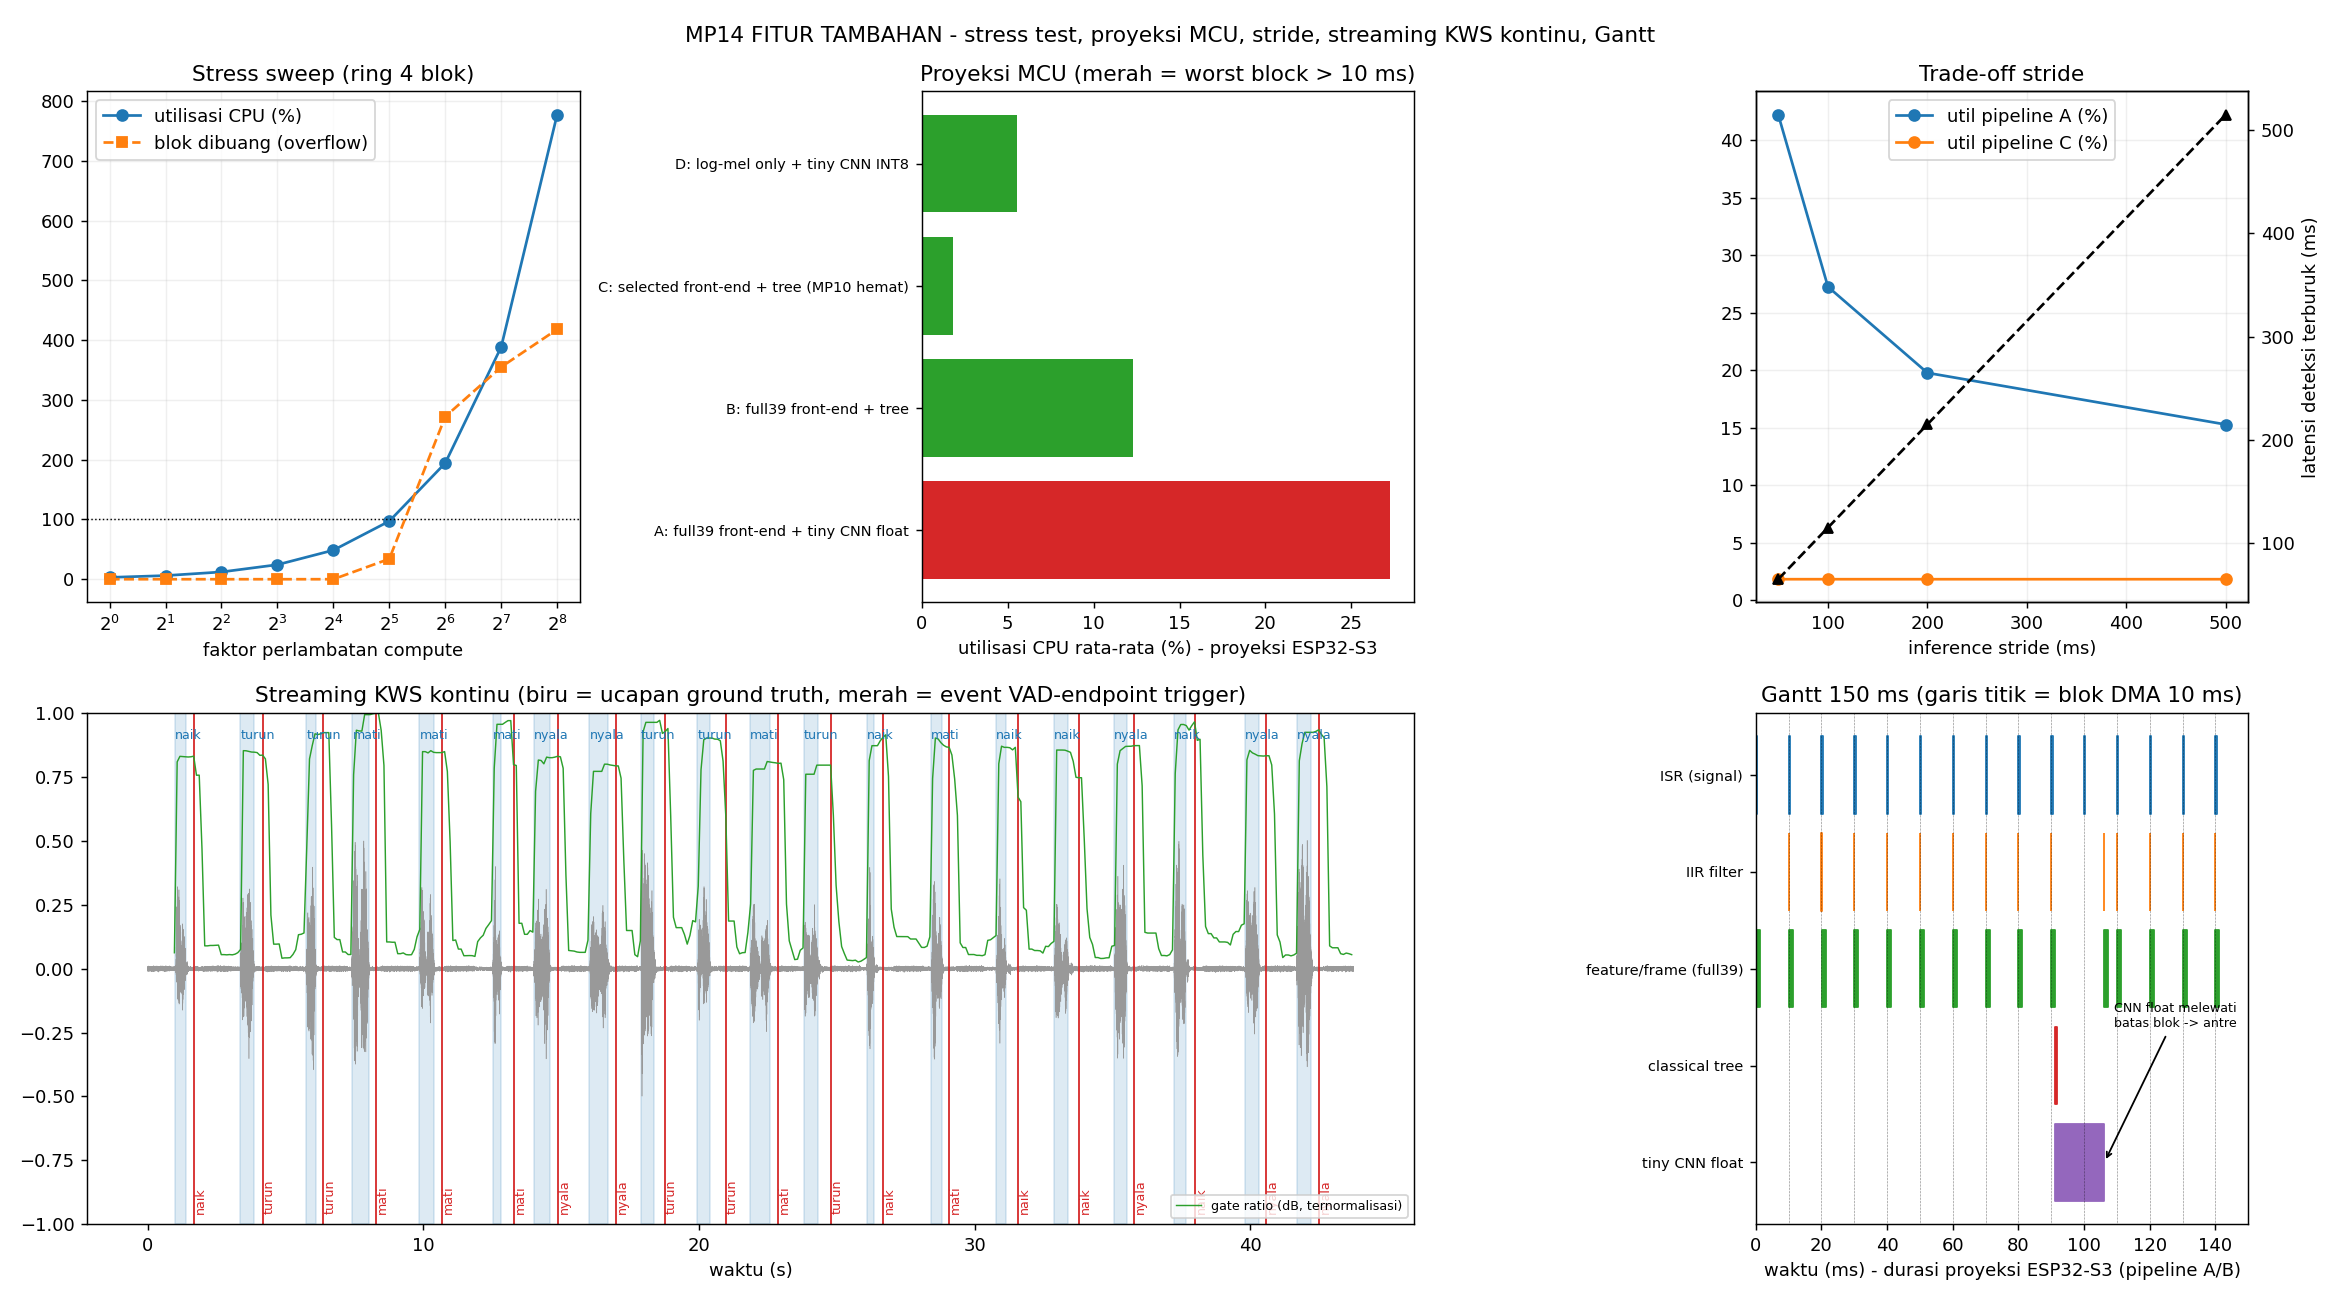

In [17]:
if "__file__" not in globals():
    from IPython.display import Image, display
    display(Image(filename=str(OUT_FIG/'mp14_extension_realtime_analysis.png'), width=1000))